# **E-commerce**

An end-to-end pipeline that turns SQL query results into business charts, using a PostgreSQL database of a synthetic European e-commerce.

## Pipeline

**PostgreSQL → SQL files → pandas DataFrames → charts (.png)**

1. **Setup:** libraries are imported and the database credentials are read from a local `credentials.env` file (never uploaded).
2. **Connection:** a SQLAlchemy engine connects Python to PostgreSQL.
3. **Loading:** every `.sql` file in `queries/` is run automatically and stored in a dictionary of DataFrames, keyed by file name (`dfs['a3_rolling_3m_revenue']`). The SQL stays the single source of truth, so no query logic is rewritten in Python.
4. **Plotting:** reusable functions (`bar_plot`, `line_plot`, `pareto_plot`) draw each chart with Seaborn and Matplotlib and export it to `charts/`.

## Analyses & Visualisations 

| Chart | Question it answers |
|-------|---------------------|
| Pareto by category | Which categories generate most of the revenue? |
| Customer segmentation (RFM) | How are customers distributed across segments? |
| Return rate by category | Which categories have the most returns and why? |
| Top products by revenue | Which products sell most and at what margin? |
| Monthly revenue | How does revenue evolve and what is the 3-month trend? |

## 0. Import & Setup

In [1]:
import os
import pandas as pd 
import numpy as np 
from sqlalchemy import create_engine, text
import seaborn as sns 
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec  
from matplotlib.colors import LinearSegmentedColormap
from dotenv import load_dotenv
from pathlib import Path
from typing import Literal

In [2]:
# Load the real credentials from credentials.env: 

load_dotenv('credentials.env')

True

In [3]:
# Create the engine connecting Python to PostgreSQL with the credentials.env:

user = os.getenv('DB_USER')
password = os.getenv('DB_PASSWORD')
port = os.getenv('DB_PORT')
host = os.getenv('DB_HOST')
db_name = os.getenv('DB_NAME')

engine = create_engine(f'postgresql+psycopg2://{user}:{password}@{host}:{port}/{db_name}')

In [15]:
# Create the Path objects:

folder = Path('queries')
output_dir = Path('charts')

# create a list with all the path objects from 'folder'
all_files = [p for p in folder.iterdir() if p.is_file()] 


# 'load_query' reads all the elements in 'all_files': 
def load_query(path,engine): 
    try: 
        with open(path, encoding='utf-8') as f: 
            read_query = f.read() 
    
        return pd.read_sql(read_query, engine)

    except: 
        print(f'Error loading: {path.name}') 
        return None



# 'dfs' has the file name without .sql as key and the corresponding dataframe as value: 
dfs = {x.stem: load_query(x, engine) for x in all_files} 

        

## 1. Functions

In [5]:
# Pareto plot function: 


def pareto_plot(df, x_col, y_bar_col, y_line_col, bar_color, line_color, title, xlabel, y_bar_label, y_line_label, filename=None): 
    
    fig, ax = plt.subplots(figsize=(5,4))
    ax.set_title(f'{title}', fontweight='bold', pad=15) 

    ax2 = ax.twinx()

    sns.despine(ax=ax, top=True, right=False)
    sns.despine(ax=ax2, top=True, right=False)

    sns.barplot(
                data=df, 
                x=x_col, 
                y=y_bar_col,  
                color=bar_color,
                legend=False,
                ax=ax 
    )


    sns.lineplot(
                 data=df,
                 x=x_col, 
                 y=y_line_col, 
                 color=line_color,
                 legend=False,
                 marker='o', 
                 markersize=6,
                 ax=ax2
    )

    
    ax.set_xlabel(f'{xlabel}')
    ax.set_ylabel(f'{y_bar_label}',labelpad=10)
    ax2.set_ylabel(f'{y_line_label}',labelpad=10)

    ax.set_ylim(0, max(y_bar_col) * 1.2)
    
    # Rotate x-ticks by 45 degrees and align them cleanly to the right: 
    
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')


    
    # Optional saving logic using fig.savefig():
    
    if filename is not None: 
        plt.savefig(f'{output_dir}/{filename}.png', dpi=300, bbox_inches='tight')
        plt.show(fig)
        plt.close(fig) #Prevent duplicate displays and memory buildup in loops


    return fig, ax, ax2
    

In [6]:
# Line plot function:

def line_plot(df, x_col, y1_col, line1_color, title, y1_col_label, x_label, y2_col=None, line2_color=None, y2_col_label=None, double_axis=False, filename=None):
    
    # 0. Resolve input series
    # Allows passing either a column name string or a pre-scaled pandas Series (e.g., df['revenue'] / 1000)
    # without triggering a KeyError during axis limit calculations:
    y1_series = df[y1_col] if isinstance(y1_col, str) else y1_col
    y2_series = df[y2_col] if isinstance(y2_col, str) else y2_col
    
    # 1. Input validation
    if not isinstance(double_axis, bool):
        raise ValueError("Invalid input for double_axis, choose from: True, False")
    if double_axis and (y2_col is None or y2_col_label is None):
        raise ValueError("y2_col and y2_col_label must be provided when double_axis=True")

    # 2. Primary axis (ax)
    fig, ax = plt.subplots(figsize=(5,4))
    sns.lineplot(
        data=df,
        x=x_col,
        y=y1_series,
        color=line1_color,
        label=y1_col_label,
        ax=ax,
    )

    ax.set_title(title, fontweight='bold', pad=15)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y1_col_label, labelpad=15)


    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

    # 3. Secondary axis (ax2) & spine/legend handling
    if double_axis:
        ax2 = ax.twinx()
        sns.lineplot(
            data=df,
            x=x_col,
            y=y2_series,
            color=line2_color,
            label=y2_col_label,
            ax=ax2,
        )
        ax2.set_ylabel(y2_col_label, labelpad=15)


        sns.despine(ax=ax, top=True, right=False)
        sns.despine(ax=ax2, top=True, right=False)


        # Combine handles/labels from both axes into one unified legend
        handles1, labels1 = ax.get_legend_handles_labels()
        handles2, labels2 = ax2.get_legend_handles_labels()
        if ax2.get_legend():
            ax2.get_legend().remove()
        ax.legend(
            handles1 + handles2,
            labels1 + labels2,
            loc="upper left",
            bbox_to_anchor=(1.2, 1),  # Extra clearance so legend doesn't overlap ax2 labels
            frameon=False,
        )
    else:
        ax2 = None
        sns.despine(ax=ax, top=True, right=True)
        ax.legend(loc="upper left", bbox_to_anchor=(1.1, 1), frameon=False)

    # 4. Optional saving
    if filename is not None:
        plt.savefig(f'{output_dir}/{filename}.png', dpi=300, bbox_inches='tight')
        plt.show(fig)
        plt.close(fig) #Prevent duplicate displays and memory buildup in loops

    return fig, (ax, ax2) if double_axis else ax

In [7]:
# Horizontal/Vertical bar plot function:

def bar_plot(df, category_col, value_col, bar_color, category_label, value_label,
             orientation: Literal['vertical', 'horizontal', 'v', 'h'], title,
             filename=None, sort=None, hue_col=None, palette=None):

    # 1. Validate first, so a bad input never leaves a half-built figure
    orientation = orientation.lower()
    valid_orientations = ['vertical', 'horizontal', 'v', 'h']
    if orientation not in valid_orientations:
        raise ValueError(f'Invalid orientation {orientation}. Choose from {valid_orientations}')
    horizontal = orientation in ('horizontal', 'h')


    #2. Sort the df
    if sort not in (None, 'asc', 'desc'):
        raise ValueError("sort must be None, 'asc' or 'desc'") 

    if sort is not None:
        df = df.sort_values(value_col, ascending=(sort == 'asc'))

    

    # 3. Map category and value to the right axis 
    if horizontal:
        x_col, y_col = value_col, category_col
        x_label, y_label = value_label, category_label
        
    else:
        x_col, y_col = category_col, value_col
        x_label, y_label = category_label, value_label




    # 4. Colour logic: color OR palette, never both
    plot_kwargs = {}
    if hue_col is None:
        plot_kwargs['color'] = bar_color
    else:
        plot_kwargs['hue'] = hue_col
        plot_kwargs['palette'] = palette
        
        # If each category has a single hue value, bars must not be dodged
        plot_kwargs['dodge'] = df.groupby(category_col)[hue_col].nunique().max() > 1

        

    # 5. Plot
    fig, ax = plt.subplots(figsize=(5,4))
    sns.barplot(data=df, x=x_col, y=y_col,
                orient='h' if horizontal else 'v', ax=ax, **plot_kwargs)

    

    # 6. Titles, labels, style
    ax.set_title(title, fontweight='bold', pad=15)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label, labelpad=10)
    sns.despine(ax=ax, top=True, right=True)

    if horizontal:
        ax.set_xlim(0, df[value_col].max() * 1.1)
    else:
        ax.set_ylim(0, df[value_col].max() * 1.1)
        #if not horizontal:
        ax.tick_params(axis='x', rotation=45)
        plt.setp(ax.get_xticklabels(), ha='right')
        

     # 7. Legend outside the plot, only when there is a hue
    if hue_col is not None:
        sns.move_legend(ax, 'upper left', bbox_to_anchor=(1.02, 1),
                        title=hue_col.replace('_', ' ').capitalize(), frameon=False)


    # 8. Optional saving
    if filename is not None:
        plt.savefig(f'{output_dir}/{filename}.png', dpi=300, bbox_inches='tight')
        plt.show(fig)
        plt.close(fig) #Prevent duplicate displays and memory buildup in loops

    return fig, ax

## 2. Charts

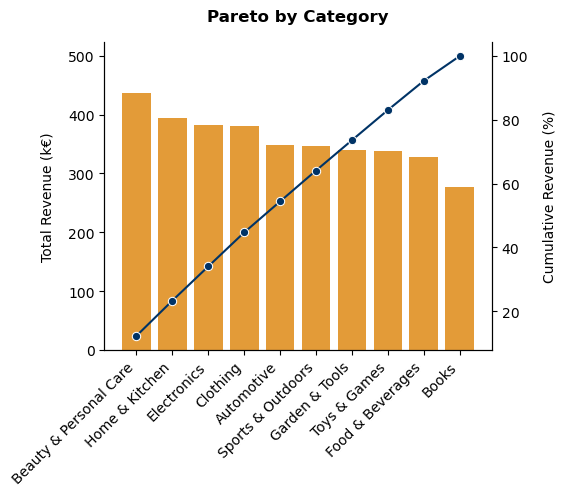

In [8]:
pareto_plot(df=dfs['a5_revenue_contribution'], 
              x_col=dfs['a5_revenue_contribution']['category_name'],
              y_bar_col=dfs['a5_revenue_contribution']['category_revenue'] / 1000, 
              y_line_col=dfs['a5_revenue_contribution']['cumulative_pct'], 
              bar_color='#FF9F1C', 
              line_color='#003366', 
              title='Pareto by Category', 
              xlabel='', 
              y_bar_label='Total Revenue (k€)',
              y_line_label= 'Cumulative Revenue (%)',
              filename='pareto_analysis'
             );

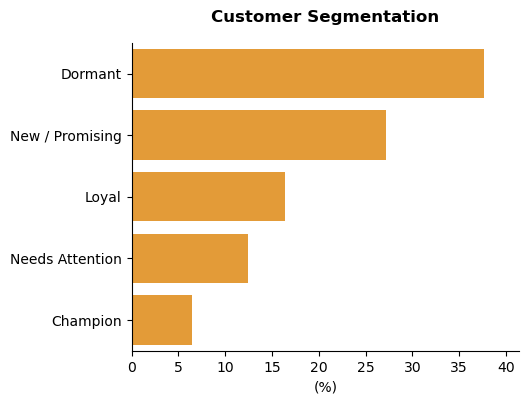

In [9]:
bar_plot(df= dfs['b5_rfm_segments'], 
         category_col='rfm_segment', 
         value_col='pct_composition', 
         bar_color='#FF9F1C',
         category_label='',
         value_label='(%)', 
         orientation='h', 
         title='Customer Segmentation', 
         filename='customer_rfm_segmentation', 
         hue_col=None,
         sort='desc'
        ); 

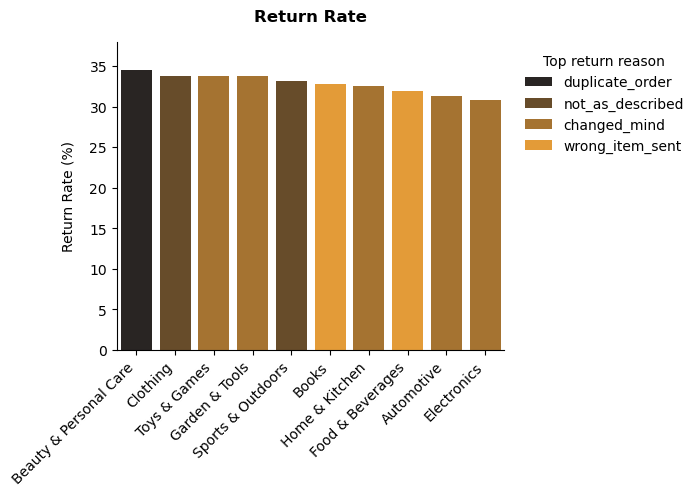

In [10]:
bar_plot(df= dfs['c3_return_by_category'], 
         category_col='category_name', 
         value_col='return_rate_pct', 
         bar_color=None,
         category_label='',
         value_label='Return Rate (%)', 
         orientation='v', 
         title='Return Rate', 
         filename='return_rate', 
         hue_col='top_return_reason',
         palette='dark:#FF9F1C',
         sort='desc'
        ); 

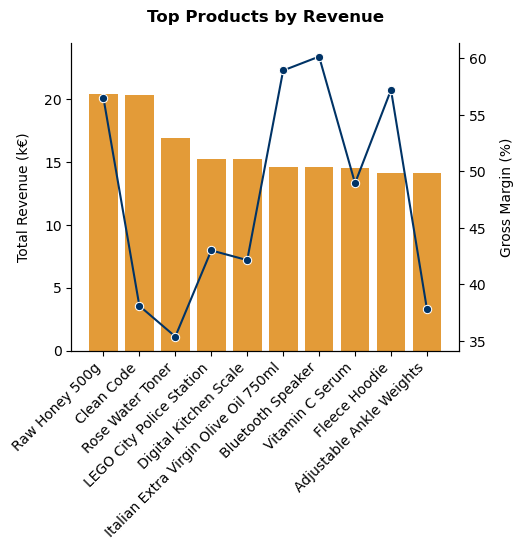

In [11]:
pareto_plot(df=dfs['c1_top_products_by_revenue'], 
            x_col=dfs['c1_top_products_by_revenue']['product_name'], 
            y_bar_col=dfs['c1_top_products_by_revenue']['total_revenue'] / 1000, 
            y_line_col=dfs['c1_top_products_by_revenue']['margin_pct'], 
            bar_color='#FF9F1C', 
            line_color='#003366',
            title='Top Products by Revenue', 
            xlabel='', 
            y_bar_label='Total Revenue (k€)', 
            y_line_label='Gross Margin (%)', 
            filename='top_products'
            );

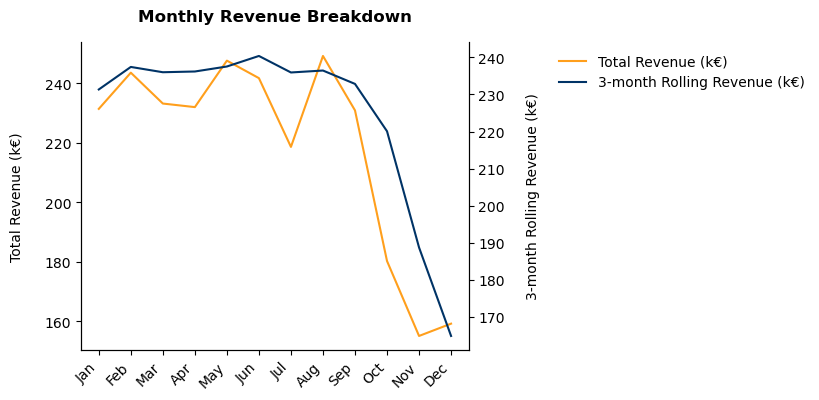

In [12]:
line_plot(df=dfs['a3_rolling_3m_revenue'], 
          x_col='month_name', 
          y1_col=dfs['a3_rolling_3m_revenue']['monthly_revenue'] / 1000, 
          y2_col=dfs['a3_rolling_3m_revenue']['rolling_3m_avg'] / 1000, 
          line1_color='#FF9F1C', 
          line2_color='#003366', 
          title='Monthly Revenue Breakdown', 
          y1_col_label='Total Revenue (k€)', 
          y2_col_label='3-month Rolling Revenue (k€)', 
          x_label='', 
          double_axis=True, 
          filename='monthly_revenue');  